In [40]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [41]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [42]:
df.info() # her sütunun adını ,boş olmayan değer sayısını ,veri tipini gösterir

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [43]:
print(df["Churn"].value_counts()) #churn sütunun da her değerin kaç gez geçtiğini gösterir
print(df["Churn"].value_counts(normalize=True)) #adet yerine oranları getir

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [44]:
df= df.drop(columns=["customerID"]) # costumerıd sütunu siler

print((df["TotalCharges"].str.strip()=="").sum) #pandas bazı sayısal değerlerde "" görünce metin kabul ediyor ve object gösteriyor .str.strip boşlukları siler7042

<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Name: TotalCharges, Length: 7043, dtype: bool>


In [45]:
print((df["TotalCharges"].str.strip() == "").sum())

11


In [46]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors= "coerce")  #Metin sütununu sayıya çevirir ve ayıya çeviremediğin bir şey görürsen hata verme, yerine NaN koy” demek
print(df["TotalCharges"].isna().sum()) #Kaç tane NaN olduğunu sayar.

df["TotalCharges"] = df["TotalCharges"].fillna(0) #NaN olan hücreleri 0 ile doldurur.
print(df["TotalCharges"].dtype) #Sütunun veri tipini gösterir.

11
float64


In [47]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0}) # map ile metin ifadeli değerleri sayıya çevirebiliyoruz

X = df.drop(columns=["Churn"]) # özellikler,yani modelin bakacağı herşey  hedef sütunu bunun içinden çıkarıyoruz
y = df["Churn"] # hedef yani modelin tahmin edeceği şey

#X büyük harf, y küçük harf yazılır. Bu bir gelenek: X bir tablo (matris), y tek bir sütun (vektör).

X = pd.get_dummies(X, drop_first=True, dtype=int) #Geri kalan metin sütunlarını 0/1 sütunlarına bölerd.get_dummies(...).drop_first=True: İlk kategori için ayrı bir sütun açmaz.
print(X.shape)
X.head()

(7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [48]:
from sklearn.model_selection import train_test_split
#"sklearn" kütüphanesinden "model selection modülünün" bölmek için kullanılarn "train_test_split" fonksiyonu
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
# x özellik y hedef sütunumuz
#test_size = 0.30 =  verinin yüzde 30 unu ayır geriye kaln yüzde 70 kullan demek
#stratify=y ayırırken hedef sütunun oranını koru
#random_state = 42 veriyi karıştırır

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp , random_state=42)

print(len(X_train), len(X_val), len(X_test))
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

4930 1056 1057
Churn
0    0.734686
1    0.265314
Name: proportion, dtype: float64
Churn
0    0.734848
1    0.265152
Name: proportion, dtype: float64
Churn
0    0.734153
1    0.265847
Name: proportion, dtype: float64


In [49]:
from sklearn.preprocessing import MinMaxScaler #ölçeklendirme için kullanılır

scaler = MinMaxScaler() # boş bir ölçekleyici oluşturuyoruz
X_train_s = scaler.fit_transform(X_train) # fit =her sütunun min max değerlerini aklında tutar trasform = bunları dönüştürür
X_val_s= scaler.transform(X_val)
X_test_s= scaler.transform(X_test)

#Train → fit_transform: min/max buradan öğrenilir.
#Val ve Test → sadece transform: train’den öğrenilen min/max kullanılır.

In [50]:
from sklearn.metrics import accuracy_score, recall_score

aptal_tahmin =np.zeros (len(y_val))

print("Accuracy:", accuracy_score(y_val, aptal_tahmin)) #Doğru tahminlerin toplam içindeki oranı
print("Recall  :", recall_score(y_val, aptal_tahmin))# Gerçekte ayrılanların kaçını yakaladık?

#Dengesiz veride accuracy tek başına yetersizdir. Model sadece çoğunluk sınıfını tahmin ederek yüksek accuracy alabilir. Bu yüzden recall, precision ve F1'e de bakılır.

Accuracy: 0.7348484848484849
Recall  : 0.0


In [51]:
from sklearn.neighbors import KNeighborsClassifier # boş bir model oluşturuyoruz

knn = KNeighborsClassifier (n_neighbors=5) # 5 komşuya bakılacak bilgisi veriyoruz . Classifier = sınıflandırıcı.
knn.fit(X_train_s, y_train) #modeli eğitiyoruz.model gözetimli öğrendiği için cevapları y ye de veriyoruz

tahmin= knn.predict(X_val_s) # tahmin et diyoruz  cevapları model vericek

print("Accuracy:", accuracy_score(y_val, tahmin))
print("Recall  :", recall_score(y_val, tahmin))

Accuracy: 0.7509469696969697
Recall  : 0.5428571428571428


In [52]:
for k in [1, 3, 5, 11, 21, 51]: # k için komşu yakınlık değerleri alır ilk 1 alır ve sonucu döndür ve devam eder
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train)

    train_acc = accuracy_score(y_train, knn.predict(X_train_s))
    val_acc   = accuracy_score(y_val, knn.predict(X_val_s))

    print(f"k={k} | train={train_acc:.3f} | val={val_acc:.3f}")

    #k küçükse model gürültüye duyarlı olur ve ezberler (overfitting). k çok büyükse sınırlar bulanıklaşır ve azınlık sınıfı ezilir. En iyi k validation verisine bakılarak seçilir.

k=1 | train=0.998 | val=0.710
k=3 | train=0.856 | val=0.753
k=5 | train=0.832 | val=0.751
k=11 | train=0.816 | val=0.755
k=21 | train=0.800 | val=0.787
k=51 | train=0.802 | val=0.774


In [53]:
from sklearn.tree import DecisionTreeClassifier # boş bir ağaç

for d in [1, 3, 5, 8, 15, None]: # ağaç istediği kadar dallanabilir
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)#max_depth=d: Ağacın derinliği. max_depth=3 en fazla 3 soru üst üste sorabilir demek.
    dt.fit(X_train, y_train) #KARAR AĞACI ÖLÇEKLENDİRMEYE İHTİYAÇ DUYMADIĞI İÇİN X_train

    train_acc = accuracy_score(y_train, dt.predict(X_train))
    val_acc   = accuracy_score(y_val, dt.predict(X_val))

    print(f"max_depth={d} | train={train_acc:.3f} | val={val_acc:.3f}")

max_depth=1 | train=0.735 | val=0.735
max_depth=3 | train=0.787 | val=0.788
max_depth=5 | train=0.808 | val=0.786
max_depth=8 | train=0.846 | val=0.769
max_depth=15 | train=0.975 | val=0.738
max_depth=None | train=0.998 | val=0.729


In [54]:
from sklearn.ensemble import RandomForestClassifier #opluluk. Birden çok modelin bir araya gelmesi.

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42) # 200 ağaç var
rf.fit(X_train, y_train)

print("train:", accuracy_score(y_train, rf.predict(X_train)))
print("val  :", accuracy_score(y_val, rf.predict(X_val)))

train: 0.8340770791075051
val  : 0.7964015151515151


In [55]:
from sklearn.metrics import precision_score, f1_score

knn = KNeighborsClassifier(n_neighbors=21).fit(X_train_s, y_train)
dt  = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

modeller = [
    ("k-NN",          knn.predict(X_val_s)),
    ("Karar Ağacı",   dt.predict(X_val)),
    ("Random Forest", rf.predict(X_val)),
]

for ad, tahmin in modeller:
    acc  = accuracy_score(y_val, tahmin)
    prec = precision_score(y_val, tahmin)
    rec  = recall_score(y_val, tahmin)
    f1   = f1_score(y_val, tahmin)

    print(ad)
    print("  Accuracy :", round(acc, 3))
    print("  Precision:", round(prec, 3))
    print("  Recall   :", round(rec, 3))
    print("  F1       :", round(f1, 3))
    print()

k-NN
  Accuracy : 0.787
  Precision: 0.596
  Recall   : 0.607
  F1       : 0.602

Karar Ağacı
  Accuracy : 0.786
  Precision: 0.608
  Recall   : 0.543
  F1       : 0.574

Random Forest
  Accuracy : 0.796
  Precision: 0.647
  Recall   : 0.511
  F1       : 0.571



In [56]:
from sklearn.metrics import confusion_matrix #2×2'lik bir boş tablo döndürür.

test_tahmin = dt.predict(X_test) #dt.predict(X_test): Karar ağacıyla test verisini tahmin et

cm = confusion_matrix(y_test, test_tahmin) ##2×2'lik bir tablo döndürür.
print(cm)

TN, FP, FN, TP = cm.ravel()
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)

[[697  79]
 [145 136]]
TN = 697
FP = 79
FN = 145
TP = 136


In [57]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_tahmin, target_names=["Kalır", "Gider"]))

              precision    recall  f1-score   support

       Kalır       0.83      0.90      0.86       776
       Gider       0.63      0.48      0.55       281

    accuracy                           0.79      1057
   macro avg       0.73      0.69      0.70      1057
weighted avg       0.78      0.79      0.78      1057



In [58]:
sonuclar = []

for ad, tahmin in modeller:
    sonuclar.append({
        "Model": ad,
        "Accuracy":  accuracy_score(y_val, tahmin),
        "Precision": precision_score(y_val, tahmin),
        "Recall":    recall_score(y_val, tahmin),
        "F1":        f1_score(y_val, tahmin),
    })

tablo = pd.DataFrame(sonuclar).round(3)
tablo

,Model,Accuracy,Precision,Recall,F1
0,k-NN,0.787,0.596,0.607,0.602
1,Karar Ağacı,0.786,0.608,0.543,0.574
2,Random Forest,0.796,0.647,0.511,0.571


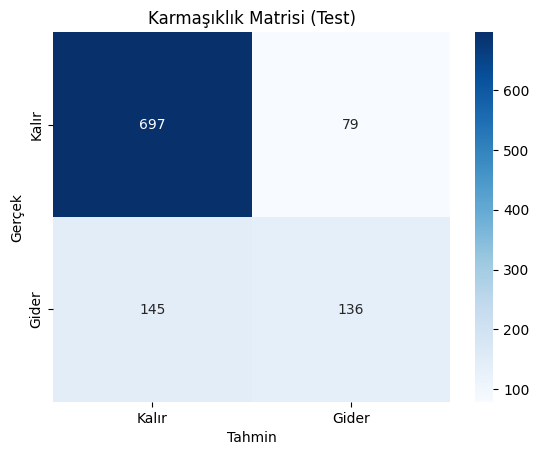

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, test_tahmin)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Kalır", "Gider"],
            yticklabels=["Kalır", "Gider"])
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Karmaşıklık Matrisi (Test)")
plt.show()